In [1]:
!nvidia-smi

Wed Oct 21 11:33:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
%cd /content
!git clone https://github.com/cheriian/patchcore-inspection.git
%cd /content/patchcore-inspection
!pip install -q faiss-cpu click pretrainedmodels timm scikit-image

/content
Cloning into 'patchcore-inspection'...
remote: Enumerating objects: 365, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 365 (delta 13), reused 8 (delta 8), pack-reused 329 (from 1)
Receiving objects: 100% (365/365), 2.02 MiB | 4.71 MiB/s, done.
Resolving deltas: 100% (56/56), done.
/content/patchcore-inspection


In [6]:
!rm -rf /content/downloads /content/data/mvtec
!mkdir -p /content/data/mvtec /content/downloads
%cd /content/downloads
!wget -q --show-progress -O mvtec_anomaly_detection.tar.xz "https://huggingface.co/datasets/ProgrammerGnome/MVTecAD/resolve/main/mvtec_anomaly_detection.tar.xz"
!ls -lh /content/downloads
!tar -xf mvtec_anomaly_detection.tar.xz -C /content/data/mvtec
!rm mvtec_anomaly_detection.tar.xz
!ls /content/data/mvtec

/content/downloads
mvtec_anomaly_detec 100%[===================>]   4.90G   261MB/s    in 38s     
total 5.0G
-rw-r--r-- 1 root root 5.0G Oct 21 11:38 mvtec_anomaly_detection.tar.xz
bottle	 carpet    leather	pill	    tile	wood
cable	 grid	   license.txt	readme.txt  toothbrush	zipper
capsule  hazelnut  metal_nut	screw	    transistor


In [7]:
!ls /content/data/mvtec/bottle
!ls /content/data/mvtec/bottle/test

ground_truth  license.txt  readme.txt  test  train
broken_large  broken_small  contamination  good


In [11]:
path = "/content/patchcore-inspection/bin/run_patchcore.py"
src = open(path).read()
src = src.replace('dataloaders["testing"].dataset.transform_std', '[0.229, 0.224, 0.225]')
src = src.replace('dataloaders["testing"].dataset.transform_mean', '[0.485, 0.456, 0.406]')
open(path, "w").write(src)
print("transform_std still present:", "transform_std" in src)
print("transform_mean still present:", "transform_mean" in src)

transform_std still present: False
transform_mean still present: False


In [13]:
%cd /content/patchcore-inspection
!env PYTHONPATH=src python bin/run_patchcore.py --gpu 0 --seed 0 --save_patchcore_model --save_segmentation_images \
  --log_group IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1_S0 --log_project MVTecAD_Results /content/drive/MyDrive/patchcore_results \
  patch_core -b wideresnet50 -le layer2 -le layer3 \
  --pretrain_embed_dimension 1024 --target_embed_dimension 1024 --anomaly_scorer_num_nn 1 --patchsize 3 \
  sampler -p 0.1 approx_greedy_coreset \
  dataset --resize 256 --imagesize 224 --num_workers 2 -d bottle -d screw -d carpet mvtec /content/data/mvtec

/content/patchcore-inspection
INFO:__main__:Command line arguments: bin/run_patchcore.py --gpu 0 --seed 0 --save_patchcore_model --save_segmentation_images --log_group IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1_S0 --log_project MVTecAD_Results /content/drive/MyDrive/patchcore_results patch_core -b wideresnet50 -le layer2 -le layer3 --pretrain_embed_dimension 1024 --target_embed_dimension 1024 --anomaly_scorer_num_nn 1 --patchsize 3 sampler -p 0.1 approx_greedy_coreset dataset --resize 256 --imagesize 224 --num_workers 2 -d bottle -d screw -d carpet mvtec /content/data/mvtec
INFO:__main__:Evaluating dataset [mvtec_bottle] (1/3)...
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights

In [14]:
import glob, pandas as pd
files = sorted(glob.glob('/content/drive/MyDrive/patchcore_results/**/results.csv', recursive=True))
print(files)
pd.read_csv(files[-1])

['/content/drive/MyDrive/patchcore_results/MVTecAD_Results/IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1_S0_1/results.csv']


,Row Names,instance_auroc,full_pixel_auroc,anomaly_pixel_auroc
0,mvtec_bottle,1.000000,0.984839,0.979561
1,mvtec_screw,0.987702,0.995248,0.993828
2,mvtec_carpet,0.985955,0.990514,0.987866
3,Mean,0.991219,0.990200,0.987085


360 images found
/content/drive/MyDrive/patchcore_results/MVTecAD_Results/IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1_S0_1/segmentation_images/mvtec_bottle/bottle_test_broken_large_000.png


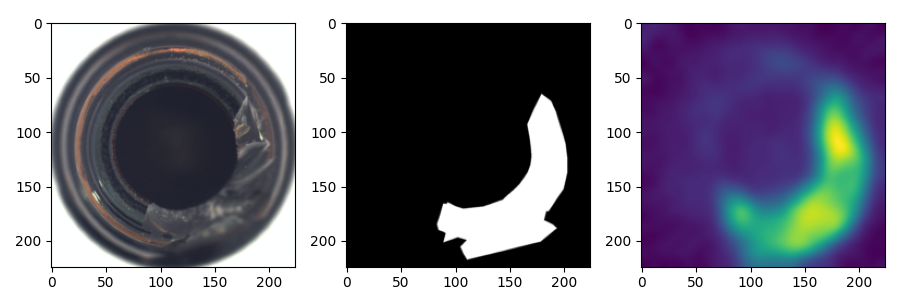

/content/drive/MyDrive/patchcore_results/MVTecAD_Results/IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1_S0_1/segmentation_images/mvtec_bottle/bottle_test_broken_large_001.png


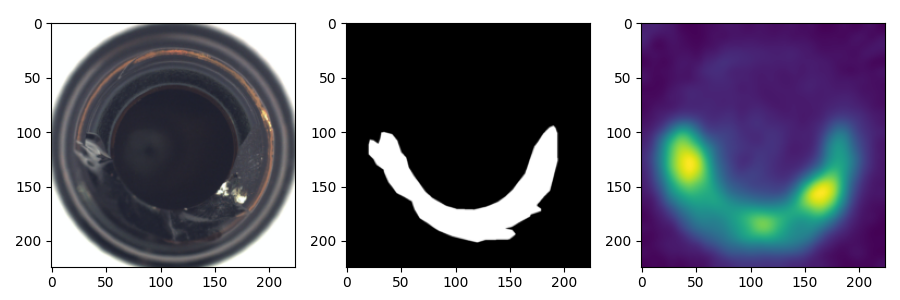

/content/drive/MyDrive/patchcore_results/MVTecAD_Results/IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1_S0_1/segmentation_images/mvtec_bottle/bottle_test_broken_large_002.png


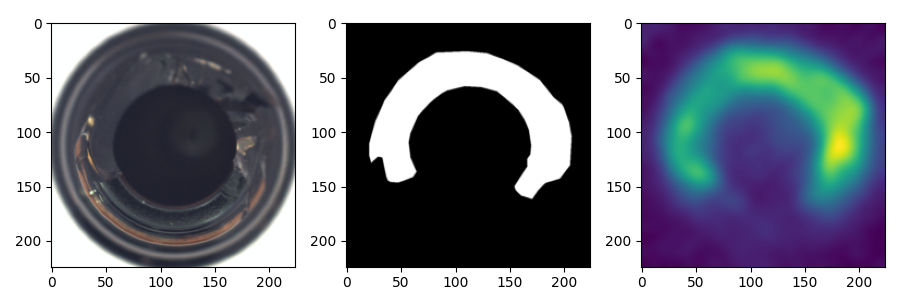

/content/drive/MyDrive/patchcore_results/MVTecAD_Results/IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1_S0_1/segmentation_images/mvtec_bottle/bottle_test_broken_large_003.png


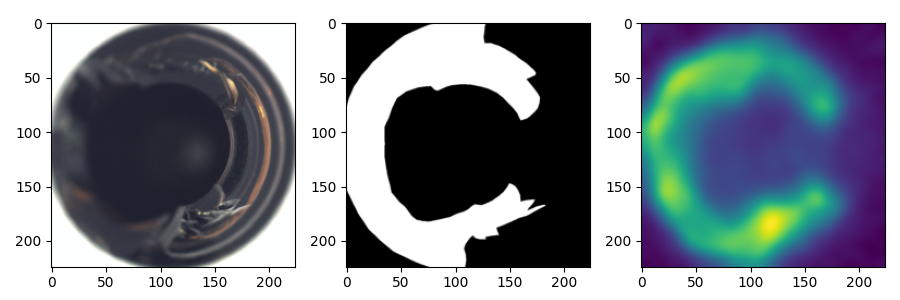

/content/drive/MyDrive/patchcore_results/MVTecAD_Results/IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1_S0_1/segmentation_images/mvtec_bottle/bottle_test_broken_large_004.png


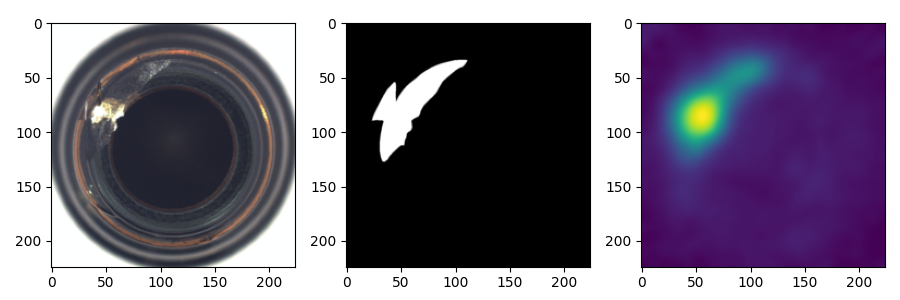

/content/drive/MyDrive/patchcore_results/MVTecAD_Results/IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1_S0_1/segmentation_images/mvtec_bottle/bottle_test_broken_large_005.png


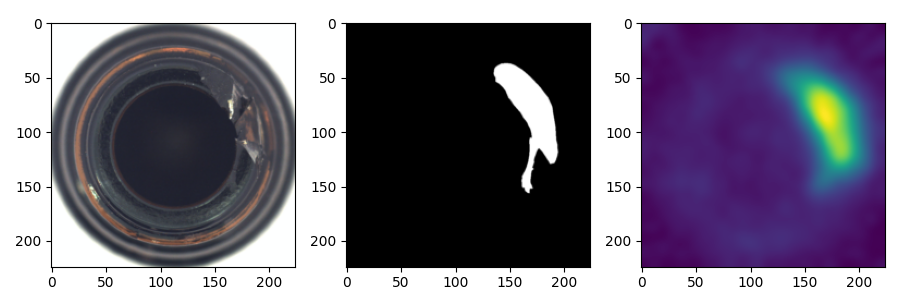

/content/drive/MyDrive/patchcore_results/MVTecAD_Results/IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1_S0_1/segmentation_images/mvtec_bottle/bottle_test_broken_large_006.png


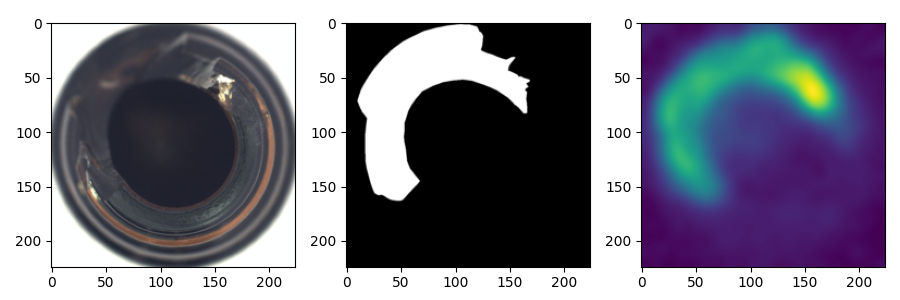

/content/drive/MyDrive/patchcore_results/MVTecAD_Results/IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1_S0_1/segmentation_images/mvtec_bottle/bottle_test_broken_large_007.png


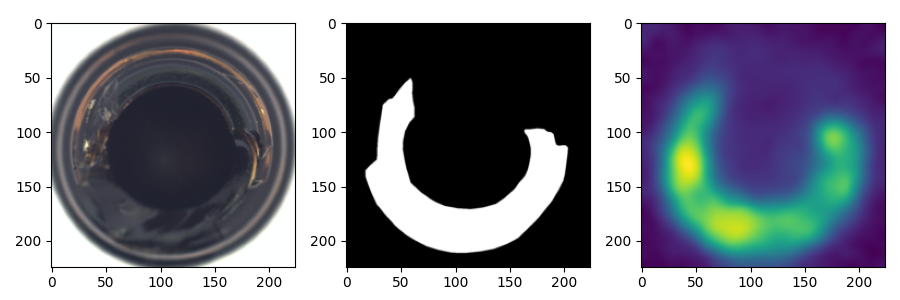

In [15]:
from IPython.display import Image, display
pngs = sorted(glob.glob('/content/drive/MyDrive/patchcore_results/**/*.png', recursive=True))
print(len(pngs), "images found")
for p in pngs[:8]:
    print(p); display(Image(p, width=600))

In [16]:
%cd /content/patchcore-inspection
!env PYTHONPATH=src python bin/run_patchcore.py --gpu 0 --seed 0 \
  --log_group IM224_WR50_L2-3_P001_D1024-1024_PS-3_AN-1_S0 --log_project MVTecAD_Results /content/drive/MyDrive/patchcore_results \
  patch_core -b wideresnet50 -le layer2 -le layer3 \
  --pretrain_embed_dimension 1024 --target_embed_dimension 1024 --anomaly_scorer_num_nn 1 --patchsize 3 \
  sampler -p 0.01 approx_greedy_coreset \
  dataset --resize 256 --imagesize 224 --num_workers 2 -d bottle -d screw -d carpet mvtec /content/data/mvtec

/content/patchcore-inspection
INFO:__main__:Command line arguments: bin/run_patchcore.py --gpu 0 --seed 0 --log_group IM224_WR50_L2-3_P001_D1024-1024_PS-3_AN-1_S0 --log_project MVTecAD_Results /content/drive/MyDrive/patchcore_results patch_core -b wideresnet50 -le layer2 -le layer3 --pretrain_embed_dimension 1024 --target_embed_dimension 1024 --anomaly_scorer_num_nn 1 --patchsize 3 sampler -p 0.01 approx_greedy_coreset dataset --resize 256 --imagesize 224 --num_workers 2 -d bottle -d screw -d carpet mvtec /content/data/mvtec
INFO:__main__:Evaluating dataset [mvtec_bottle] (1/3)...
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed i

In [17]:
import glob, pandas as pd
for f in sorted(glob.glob('/content/drive/MyDrive/patchcore_results/MVTecAD_Results/*/results.csv')):
    print(f.split('/')[-2])
    display(pd.read_csv(f))

IM224_WR50_L2-3_P001_D1024-1024_PS-3_AN-1_S0


,Row Names,instance_auroc,full_pixel_auroc,anomaly_pixel_auroc
0,mvtec_bottle,1.000000,0.984742,0.979442
1,mvtec_screw,0.973970,0.994058,0.992628
2,mvtec_carpet,0.984350,0.990011,0.987303
3,Mean,0.986107,0.989604,0.986458


IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1_S0_1


,Row Names,instance_auroc,full_pixel_auroc,anomaly_pixel_auroc
0,mvtec_bottle,1.000000,0.984839,0.979561
1,mvtec_screw,0.987702,0.995248,0.993828
2,mvtec_carpet,0.985955,0.990514,0.987866
3,Mean,0.991219,0.990200,0.987085


bottle_test_contamination_012.png


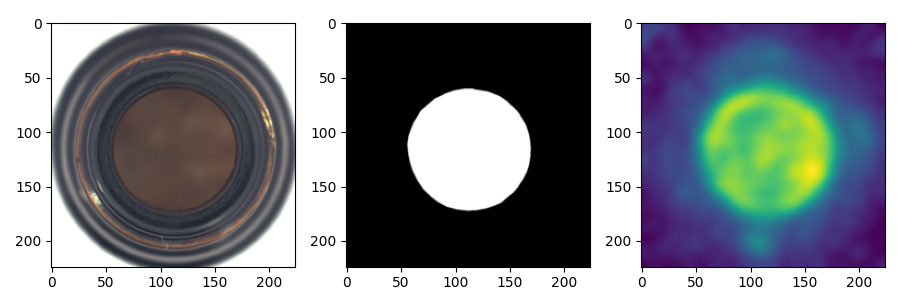

bottle_test_broken_small_004.png


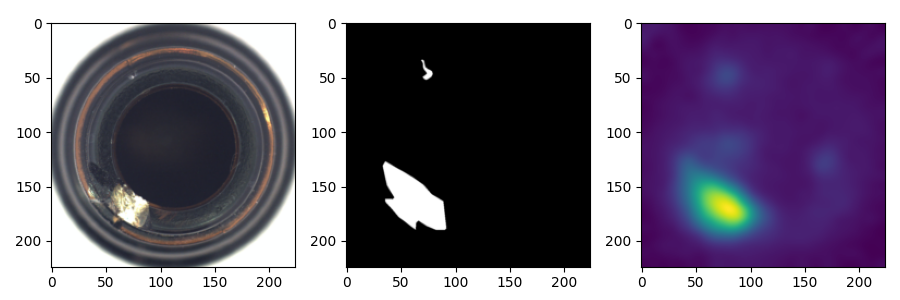

bottle_test_contamination_006.png


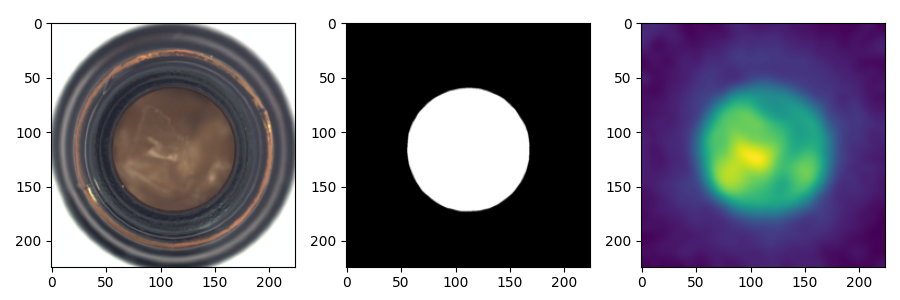

screw_test_thread_top_017.png


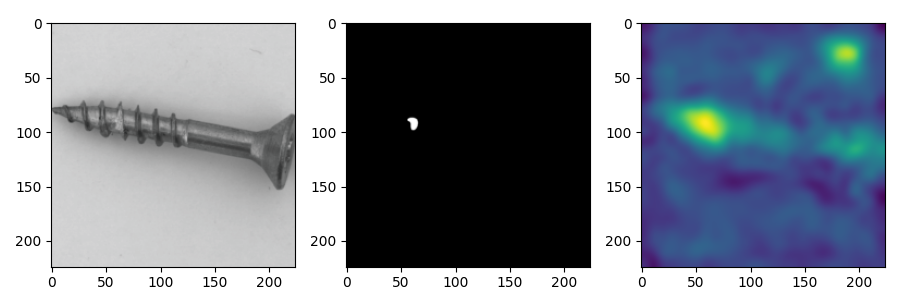

screw_test_scratch_neck_005.png


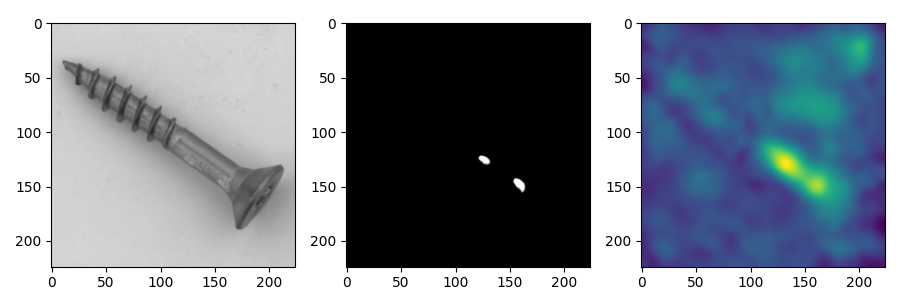

screw_test_manipulated_front_005.png


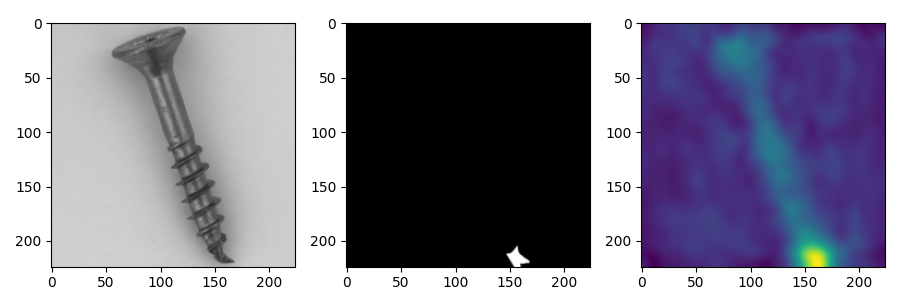

carpet_test_cut_014.png


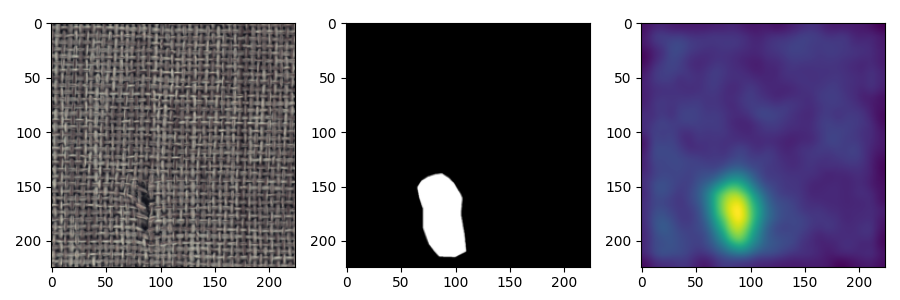

carpet_test_metal_contamination_012.png


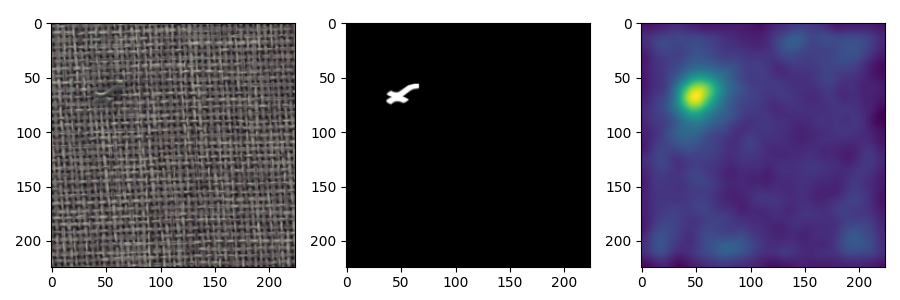

carpet_test_metal_contamination_009.png


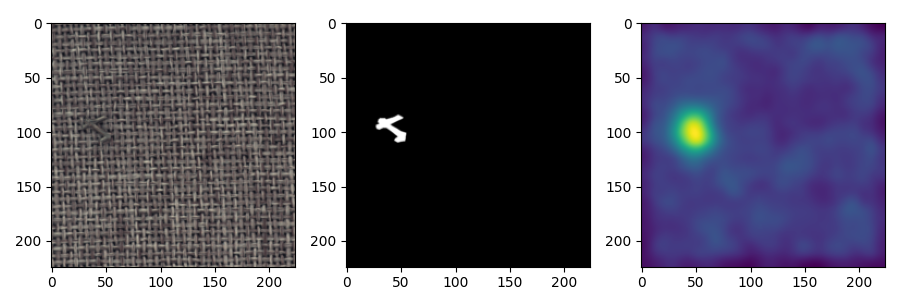

Saved to /content/drive/MyDrive/review1_figures


In [18]:
import glob, os, shutil, random
from IPython.display import Image, display
random.seed(0)
base = '/content/drive/MyDrive/patchcore_results/MVTecAD_Results/IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1_S0_1/segmentation_images'
out = '/content/drive/MyDrive/review1_figures'
os.makedirs(out, exist_ok=True)
for cat in ['mvtec_bottle', 'mvtec_screw', 'mvtec_carpet']:
    defects = [p for p in glob.glob(f'{base}/{cat}/*.png') if '_good_' not in p]
    for p in random.sample(defects, 3):
        shutil.copy(p, out)
        print(os.path.basename(p)); display(Image(p, width=600))
print("Saved to", out)